In [1]:
import datetime
import pandas as pd
import mplfinance as mpf
import matplotlib.pyplot as plt
import seaborn as sn

from lutils.fin.data_loader import load

In [1]:
plt.rcParams['font.sans-serif'] = ['SimHei']

NameError: name 'plt' is not defined

In [2]:
%matplotlib widget

In [3]:
from lutils.fin.data_loader import load

In [4]:
pd.set_option('display.float_format', '{:.2f}'.format)

### https://www.simnow.com.cn/product.action    保证金 手续费

In [5]:
handling_fees_future_val = None     # 期货手续费  固定金额
handling_fees_future_per = 0.001    # 期货手续费  百分比
handling_fees_option_val = 2        # 期权手续费  固定金额
handling_fees_option_per = None     # 期权手续费  百分比
multiplier = 10                     # 合约乘数
margin_level = 0.16                 # 保证金比例

In [6]:
min_range = [[543, 612], [632, 687], [813, 897], [1263, 1377]]
# min_range = [[542, 613], [631, 688], [812, 898], [1262, 1378]]

In [7]:
start_date = '2024-03-01'

In [8]:
exchange = 'SHFE' # SHFE CZCE
f_symbol = 'rb2410'

prices = []
c_symbols = []
p_symbols = []
for i in range(3700, 3950, 50): # 3250, 4350, 50 # 3350, 4050, 50
    prices.append(i)

    c_symbols.append('rb2410C%s' % i)
    p_symbols.append('rb2410P%s' % i)

In [9]:
# exchange = 'CZCE' # SHFE CZCE
# f_symbol = 'TA406'

# prices = []
# c_symbols = []
# p_symbols = []
# for i in range(5200, 6800, 100):
#     prices.append(i)

#     c_symbols.append('%sC%s' % (f_symbol, i))
#     p_symbols.append('%sP%s' % (f_symbol, i))

In [10]:
f_df = load(exchange, f_symbol, start_date, resample='1s')

load Y:/ctp_data\2024-03-04\SHFE.rb2410.h5
load Y:/ctp_data\2024-03-05\SHFE.rb2410.h5
load Y:/ctp_data\2024-03-06\SHFE.rb2410.h5
load Y:/ctp_data\2024-03-07\SHFE.rb2410.h5
load Y:/ctp_data\2024-03-08\SHFE.rb2410.h5
load Y:/ctp_data\2024-03-11\SHFE.rb2410.h5
load Y:/ctp_data\2024-03-12\SHFE.rb2410.h5
load Y:/ctp_data\2024-03-13\SHFE.rb2410.h5
load Y:/ctp_data\2024-03-14\SHFE.rb2410.h5
load Y:/ctp_data\2024-03-15\SHFE.rb2410.h5
load Y:/ctp_data\2024-03-18\SHFE.rb2410.h5
load Y:/ctp_data\2024-03-19\SHFE.rb2410.h5
load Y:/ctp_data\2024-03-20\SHFE.rb2410.h5
load Y:/ctp_data\2024-03-21\SHFE.rb2410.h5
load Y:/ctp_data\2024-03-22\SHFE.rb2410.h5
load Y:/ctp_data\2024-03-25\SHFE.rb2410.h5
load Y:/ctp_data\2024-03-26\SHFE.rb2410.h5
load Y:/ctp_data\2024-03-27\SHFE.rb2410.h5
load Y:/ctp_data\2024-03-28\SHFE.rb2410.h5
load Y:/ctp_data\2024-03-29\SHFE.rb2410.h5
load Y:/ctp_data\2024-04-01\SHFE.rb2410.h5
load Y:/ctp_data\2024-04-02\SHFE.rb2410.h5
load Y:/ctp_data\2024-04-03\SHFE.rb2410.h5
load Y:/ctp

In [11]:
c_dfs = {}
for c_symbol in c_symbols:
    c_dfs[c_symbol] = load(exchange, c_symbol, start_date, resample='1s')

load Y:/ctp_data\2024-03-04\SHFE.rb2410C3700.h5
load Y:/ctp_data\2024-03-05\SHFE.rb2410C3700.h5
load Y:/ctp_data\2024-03-06\SHFE.rb2410C3700.h5
load Y:/ctp_data\2024-03-07\SHFE.rb2410C3700.h5
load Y:/ctp_data\2024-03-08\SHFE.rb2410C3700.h5
load Y:/ctp_data\2024-03-11\SHFE.rb2410C3700.h5
load Y:/ctp_data\2024-03-12\SHFE.rb2410C3700.h5
load Y:/ctp_data\2024-03-13\SHFE.rb2410C3700.h5
load Y:/ctp_data\2024-03-14\SHFE.rb2410C3700.h5
load Y:/ctp_data\2024-03-15\SHFE.rb2410C3700.h5
load Y:/ctp_data\2024-03-18\SHFE.rb2410C3700.h5
load Y:/ctp_data\2024-03-19\SHFE.rb2410C3700.h5
load Y:/ctp_data\2024-03-20\SHFE.rb2410C3700.h5
load Y:/ctp_data\2024-03-21\SHFE.rb2410C3700.h5
load Y:/ctp_data\2024-03-22\SHFE.rb2410C3700.h5
load Y:/ctp_data\2024-03-25\SHFE.rb2410C3700.h5
load Y:/ctp_data\2024-03-26\SHFE.rb2410C3700.h5
load Y:/ctp_data\2024-03-27\SHFE.rb2410C3700.h5
load Y:/ctp_data\2024-03-28\SHFE.rb2410C3700.h5
load Y:/ctp_data\2024-03-29\SHFE.rb2410C3700.h5
load Y:/ctp_data\2024-04-01\SHFE.rb2410C

In [12]:
p_dfs = {}
for p_symbol in p_symbols:
    p_dfs[p_symbol] = load(exchange, p_symbol, start_date, resample='1s')

load Y:/ctp_data\2024-03-04\SHFE.rb2410P3700.h5
load Y:/ctp_data\2024-03-05\SHFE.rb2410P3700.h5
load Y:/ctp_data\2024-03-06\SHFE.rb2410P3700.h5
load Y:/ctp_data\2024-03-07\SHFE.rb2410P3700.h5
load Y:/ctp_data\2024-03-08\SHFE.rb2410P3700.h5
load Y:/ctp_data\2024-03-11\SHFE.rb2410P3700.h5
load Y:/ctp_data\2024-03-12\SHFE.rb2410P3700.h5
load Y:/ctp_data\2024-03-13\SHFE.rb2410P3700.h5
load Y:/ctp_data\2024-03-14\SHFE.rb2410P3700.h5
load Y:/ctp_data\2024-03-15\SHFE.rb2410P3700.h5
load Y:/ctp_data\2024-03-18\SHFE.rb2410P3700.h5
load Y:/ctp_data\2024-03-19\SHFE.rb2410P3700.h5
load Y:/ctp_data\2024-03-20\SHFE.rb2410P3700.h5
load Y:/ctp_data\2024-03-21\SHFE.rb2410P3700.h5
load Y:/ctp_data\2024-03-22\SHFE.rb2410P3700.h5
load Y:/ctp_data\2024-03-25\SHFE.rb2410P3700.h5
load Y:/ctp_data\2024-03-26\SHFE.rb2410P3700.h5
load Y:/ctp_data\2024-03-27\SHFE.rb2410P3700.h5
load Y:/ctp_data\2024-03-28\SHFE.rb2410P3700.h5
load Y:/ctp_data\2024-03-29\SHFE.rb2410P3700.h5
load Y:/ctp_data\2024-04-01\SHFE.rb2410P

In [13]:
fdf = f_df[['last_price', 'bid_price1', 'ask_price1']].rename(columns={'last_price': 'f_last_price', 'bid_price1': 'f_sell_price', 'ask_price1': 'f_buy_price'})

In [14]:
cdfs = {}
for c_symbol in c_symbols:
    cdfs[c_symbol] = c_dfs[c_symbol][['last_price', 'bid_price1', 'ask_price1']].rename(
        columns={'last_price': 'c_last_price_%s' % c_symbol, 'bid_price1': 'c_sell_price_%s' % c_symbol, 'ask_price1': 'c_buy_price_%s' % c_symbol})

In [15]:
pdfs = {}
for p_symbol in p_symbols:
    pdfs[p_symbol] = p_dfs[p_symbol][['last_price', 'bid_price1', 'ask_price1']].rename(
        columns={'last_price': 'p_last_price_%s' % p_symbol, 'bid_price1': 'p_sell_price_%s' % p_symbol, 'ask_price1': 'p_buy_price_%s' % p_symbol})

### 平价套利

In [37]:
fdf.shape

(1248505, 3)

In [38]:
df = fdf # .merge(cdf, how='left', left_index=True, right_index=True)

for c_symbol in c_symbols:
    df = df.merge(cdfs[c_symbol], how='left', left_index=True, right_index=True)

for p_symbol in p_symbols:
    df = df.merge(pdfs[p_symbol], how='left', left_index=True, right_index=True)

In [39]:
df = df.ffill()
# df = df.loc['2024-04-28':]

In [40]:
df['min'] = df.index.hour * 60 + df.index.minute

In [41]:
_dfs = []
for s, e in min_range:
    _dfs.append(df[(df['min'] > s) & (df['min'] < e)])

In [42]:
df = pd.concat(_dfs, axis=0).sort_index()

In [43]:
# df.iloc[4078:].head()

In [44]:
df['spread_f'] = df['f_buy_price'] - df['f_sell_price']

In [45]:
# 平价套利
for price in prices:
    # df.loc[:, 'arb_%s' % price] = df['f_last_price'] - price - df['c_last_price_rb2410C%s' % price] + df['p_last_price_rb2410P%s' % price]
    
    # df.loc[:, 'spread_c_%s' % price] = df['c_buy_price_rb2410C%s' % price] - df['c_sell_price_rb2410C%s' % price]
    # df.loc[:, 'spread_p_%s' % price] = df['p_buy_price_rb2410P%s' % price] - df['p_sell_price_rb2410P%s' % price]
    
    # df.loc[:, 'negative_%s' % price] = df['f_sell_price'] - price - df['c_buy_price_rb2410C%s' % price] + df['p_sell_price_rb2410P%s' % price]
    # df.loc[:, 'positive_%s' % price] = price + df['c_sell_price_rb2410C%s' % price] - df['p_buy_price_rb2410P%s' % price] - df['f_buy_price']

    _d = pd.concat(
        [
            df['f_last_price'] - price - df['c_last_price_%sC%s' % (f_symbol, price)] + df['p_last_price_%sP%s' % (f_symbol, price)],
            ((df['f_buy_price'] + df['f_sell_price']) / 2) - price -\
            ((df['c_buy_price_%sC%s' % (f_symbol, price)] + df['c_sell_price_%sC%s' % (f_symbol, price)]) / 2) +\
            ((df['p_buy_price_%sP%s' % (f_symbol, price)] + df['p_sell_price_%sP%s' % (f_symbol, price)]) / 2),
            
            df['spread_f'] + df['c_buy_price_%sC%s' % (f_symbol, price)] - df['c_sell_price_%sC%s' % (f_symbol, price)] + df['p_buy_price_%sP%s' % (f_symbol, price)] - df['p_sell_price_%sP%s' % (f_symbol, price)],
            df['c_buy_price_%sC%s' % (f_symbol, price)] - df['c_sell_price_%sC%s' % (f_symbol, price)],
            df['p_buy_price_%sP%s' % (f_symbol, price)] - df['p_sell_price_%sP%s' % (f_symbol, price)],
            
            df['f_sell_price'] - price - df['c_buy_price_%sC%s' % (f_symbol, price)] + df['p_sell_price_%sP%s' % (f_symbol, price)],
            price + df['c_sell_price_%sC%s' % (f_symbol, price)] - df['p_buy_price_%sP%s' % (f_symbol, price)] - df['f_buy_price'],
            
            df['f_sell_price'] * margin_level * multiplier - df['c_buy_price_%sC%s' % (f_symbol, price)] * multiplier + df['p_sell_price_%sP%s' % (f_symbol, price)] * margin_level * multiplier,
            df['c_sell_price_%sC%s' % (f_symbol, price)] * margin_level * multiplier - df['p_buy_price_%sP%s' % (f_symbol, price)] * multiplier - df['f_buy_price'] * margin_level * multiplier,
        ], 
        axis=1, 
        keys=
        [
            'arb_%s' % price, 
            'arb_mid_%s' % price, 

            'spread_%s' % price, 
            'spread_c_%s' % price, 
            'spread_p_%s' % price, 

            'negative_%s' % price, 
            'positive_%s' % price, 
            
            'negative_price_%s' % price, 
            'positive_price_%s' % price
        ])

    df = pd.concat([df, _d], axis=1)

# df['negative'] = df['f_sell_price'] - 3550 - df['c_buy_price'] + df['p_sell_price']
# df['positive'] = 3550 + df['c_sell_price'] - df['p_buy_price'] - df['f_buy_price']

In [53]:
# df = df.loc['2024-04-27':]

In [54]:
# df.head()

In [55]:
# df = df[(df.negative > -1000000) & (df.negative < 1000000)]

# for price in prices:
#     df = df[(df['negative_%s' % price] > -1000000) & (df['negative_%s' % price] < 1000000) & (df['positive_%s' % price] > -1000000) & (df['positive_%s' % price] < 1000000)]

In [56]:
# df.head()

In [57]:
# plt.close()
# for price in prices[11:12]:
   
#     plt.plot(df['negative_%s' % price].values[-5300:-3000], label='negative_%s' % price)
#     plt.plot(df['positive_%s' % price].values[-5300:-3000], label='positive_%s' % price)

# # plt.plot(df['negative_%s' % price].values, label='negative_%s' % price)

# plt.legend()
# plt.show()

In [58]:
plt.close()

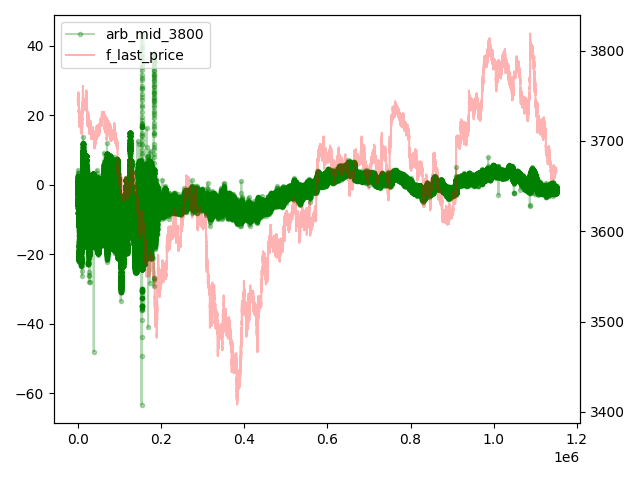

In [60]:
plt.close()
# for _price in prices[11:12]:
_price = 3800 # 3900 6100
_price2 = 3900

_start = 2000000

fig, ax1 = plt.subplots()
# ax1.plot(df['arb_%s' % _price].values[-_start:], label='arb_%s' % _price, color='g', alpha=.3)
# ax1.plot(df['arb_%s' % _price2].values[-_start:], label='arb_%s' % _price2, color='springgreen')
ax1.plot(df['arb_mid_%s' % _price].values[-_start:], marker='.', label='arb_mid_%s' % _price, color='g', alpha=.3)

# ax1.plot(df['negative_%s' % _price].values[-_start:], marker='.', label='negative_%s' % _price, color='y', alpha=.5)
# ax1.plot(df['positive_%s' % _price].values[-_start:], marker='.', label='positive_%s' % _price, color='b', alpha=.5)

# ax1.plot(df['spread_%s' % _price].values[-_start:], marker='.', label='spread_%s' % _price, color='blueviolet', alpha=.2)

# ax1.plot((df['negative_%s' % _price] + df['spread_%s' % _price]).values[-_start:], marker='.', label='negative_%s' % _price, color='royalblue', alpha=.5)

# ax1.plot(df['spread_f'].values[-_start:], marker='.', label='spread_f', color='purple', alpha=.5)
# ax1.plot(df['spread_c_%s' % _price].values[-_start:], marker='.', label='spread_c_%s' % _price, color='orchid', alpha=.5)
# ax1.plot(df['spread_p_%s' % _price].values[-_start:], marker='.', label='spread_c_%s' % _price, color='deeppink', alpha=.5)


ax2 = ax1.twinx()
# ax2.plot(df.loc['2024-03-20':]['arb_mid_%s' % _price].values[-_start:], marker='.', label='arb_mid_%s' % _price, color='g', alpha=.3)
# ax2.plot(df['spread_c_%s' % _price].values[-_start:], label='spread_c_%s' % _price, color='r')
ax2.plot(df['f_last_price'].values[-_start:], label='f_last_price', color='r', alpha=.3)
# ax2.plot(df['negative_price_%s' % _price].values[-_start:], label='negative_price_%s' % _price, color='orchid')
# ax2.plot(df['positive_price_%s' % _price].values[-_start:], label='positive_price_%s' % _price, color='deeppink')


lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc=0)


fig.tight_layout()
plt.show()

In [39]:
# _price = 3800
# df[df['positive_%s' % _price] <= -9][['positive_%s' % _price]].head()

In [40]:
# _price11 = 3800
# df.loc['2024-04-22 21:04:55':][df.loc['2024-04-22 21:04:55':]['positive_%s' % _price11] > 2][['positive_%s' % _price11]].head()

In [38]:
# _price1 = 3800
# df.loc['2024-04-22 21:04:55':][['positive_%s' % _price1, 'negative_%s' % _price1, 'f_sell_price', 'f_buy_price', 'c_sell_price_rb2410C%s' % _price1, 'c_buy_price_rb2410C%s' % _price1, 'p_sell_price_rb2410P%s' % _price1, 'p_buy_price_rb2410P%s' % _price1]].head()

##### df['f_sell_price'] - price - df['c_buy_price_%sC%s' % (f_symbol, price)] + df['p_sell_price_%sP%s' % (f_symbol, price)],
##### 3673.0 - 3800 - 93.5 + 221.0

##### price + df['c_sell_price_%sC%s' % (f_symbol, price)] - df['p_buy_price_%sP%s' % (f_symbol, price)] - df['f_buy_price'],
##### 3800 + 91 - 226.0 - 3674.0
f_buy_price     c_sell_price_rb2410C3800       p_buy_price_rb2410P3800  
3674.0          91.0                           226.0  

f_sell_price    c_buy_price_rb2410C3800        p_sell_price_rb2410P3800  
3671.0          86.0                           210.0  
-3              5                              -16  

f_sell_price    c_buy_price_rb2410C3800        p_sell_price_rb2410P3800  
3672.0          89.0                           221.0  
-2              2                              -5  

##################
f_sell_price    c_buy_price_rb2410C3800        p_sell_price_rb2410P3800  
3673.0          93.5                           221.0  

f_buy_price     c_sell_price_rb2410C3800       p_buy_price_rb2410P3800  
3672.0          85.5                           211.0  
1               -8                             10  

f_buy_price     c_sell_price_rb2410C3800       p_buy_price_rb2410P3800  
3673.0          88.5                           223.0  
0               -5                             -2  

f_sell_price    f_buy_price    c_sell_price_rb2410C3800	   c_buy_price_rb2410C3800     p_sell_price_rb2410P3800      p_buy_price_rb2410P3800  
3672.0          3673.0         88.5	                       89.0                        221.0                         223.0  

In [41]:
# _price1 = 3800
# df.loc['2024-05-10 09:27:07':][['positive_%s' % _price1, 'negative_%s' % _price1, 'f_sell_price', 'f_buy_price', 'c_sell_price_rb2410C%s' % _price1, 'c_buy_price_rb2410C%s' % _price1, 'p_sell_price_rb2410P%s' % _price1, 'p_buy_price_rb2410P%s' % _price1]].head()

In [42]:
# _price11 = 3800
# df.loc['2024-04-22 21:04:55':][df.loc['2024-04-22 21:04:55':]['negative_%s' % _price11] > 4][['negative_%s' % _price11]].head()

In [43]:
# df.loc['2024-04-23 09:58:33':][['positive_%s' % _price1, 'negative_%s' % _price1, 'f_sell_price', 'f_buy_price', 'c_sell_price_rb2410C%s' % _price1, 'c_buy_price_rb2410C%s' % _price1, 'p_sell_price_rb2410P%s' % _price1, 'p_buy_price_rb2410P%s' % _price1]].head()

### arb_mid

In [44]:
_price = 3800
df['arb_mid_%s' % _price].describe()

count   978600.00
mean        -2.93
std          4.95
min        -63.25
25%         -6.25
50%         -2.25
75%          1.25
max         43.50
Name: arb_mid_3800, dtype: float64

In [51]:
_price = 3800
print(df[df['arb_mid_%s' % _price] >= 5][['arb_mid_%s' % _price]].tail())
print(df.loc['2024-04-24 10:09:32':][df['arb_mid_%s' % _price] <= -4][['arb_mid_%s' % _price]].head())

                     arb_mid_3800
datetime                         
2024-04-24 10:09:29          5.00
2024-04-24 10:09:30          5.00
2024-04-24 10:09:31          5.00
2024-04-24 10:09:32          5.00
2024-05-16 11:25:01          5.00
                     arb_mid_3800
datetime                         
2024-05-10 09:33:55         -4.25
2024-05-10 09:33:56         -4.25
2024-05-10 09:33:59         -4.25
2024-05-10 09:34:00         -4.25
2024-05-10 09:54:59         -4.25


C:\Users\left\AppData\Local\Temp\ipykernel_3852\3194818366.py:3: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  print(df.loc['2024-04-24 10:09:32':][df['arb_mid_%s' % _price] <= -4][['arb_mid_%s' % _price]].head())


In [185]:
_price1 = 3800
df.loc['2024-04-09 09:20:40':][['f_sell_price', 'f_buy_price', 'c_sell_price_rb2410C%s' % _price1, 'c_buy_price_rb2410C%s' % _price1, 'p_sell_price_rb2410P%s' % _price1, 'p_buy_price_rb2410P%s' % _price1]].head(1)

,f_sell_price,f_buy_price,c_sell_price_rb2410C3800,c_buy_price_rb2410C3800,p_sell_price_rb2410P3800,p_buy_price_rb2410P3800
datetime,,,,,,
2024-04-09 09:20:40,3541.00,3542.00,75.00,76.00,324.00,327.50


In [186]:
_price1 = 3800
df.loc['2024-04-22 10:40:26':][['f_sell_price', 'f_buy_price', 'c_sell_price_rb2410C%s' % _price1, 'c_buy_price_rb2410C%s' % _price1, 'p_sell_price_rb2410P%s' % _price1, 'p_buy_price_rb2410P%s' % _price1]].head(1)

,f_sell_price,f_buy_price,c_sell_price_rb2410C3800,c_buy_price_rb2410C3800,p_sell_price_rb2410P3800,p_buy_price_rb2410P3800
datetime,,,,,,
2024-04-22 10:40:26,3686.00,3687.00,100.50,101.00,217.50,221.00


##################  
f_buy_price     c_sell_price_rb2410C3800       p_buy_price_rb2410P3800  
3542.00         75.00                          327.50  

f_sell_price    c_buy_price_rb2410C3800        p_sell_price_rb2410P3800  
3686.00         101.00                         217.50  
144             -26                            -110  


##################
f_sell_price    c_buy_price_rb2410C3800        p_sell_price_rb2410P3800  
3541.00         76.00                          324.00  

f_buy_price     c_sell_price_rb2410C3800       p_buy_price_rb2410P3800  
3687.00         100.50                         221.00  
-146            24.5                           103

In [28]:
_price = 3800
df['arb_mid_%s' % _price].describe()

count   317580.00
mean         0.97
std          2.05
min         -5.00
25%         -0.75
50%          1.25
75%          2.25
max          7.00
Name: arb_mid_3800, dtype: float64

In [38]:
_price = 3800
print(df[df['arb_mid_%s' % _price] <= -4][['arb_mid_%s' % _price]].head())
print(df[df['arb_mid_%s' % _price] >= 5][['arb_mid_%s' % _price]].tail())

                     arb_mid_3800
datetime                         
2024-05-10 09:33:55         -4.25
2024-05-10 09:33:56         -4.25
2024-05-10 09:33:59         -4.25
2024-05-10 09:34:00         -4.25
2024-05-10 09:54:59         -4.25
                     arb_mid_3800
datetime                         
2024-04-24 10:09:29          5.00
2024-04-24 10:09:30          5.00
2024-04-24 10:09:31          5.00
2024-04-24 10:09:32          5.00
2024-05-16 11:25:01          5.00


In [34]:
_price1 = 3800
df.loc['2024-05-10 09:33:55':][['f_sell_price', 'f_buy_price', 'c_sell_price_rb2410C%s' % _price1, 'c_buy_price_rb2410C%s' % _price1, 'p_sell_price_rb2410P%s' % _price1, 'p_buy_price_rb2410P%s' % _price1]].head(1)

,f_sell_price,f_buy_price,c_sell_price_rb2410C3800,c_buy_price_rb2410C3800,p_sell_price_rb2410P3800,p_buy_price_rb2410P3800
datetime,,,,,,
2024-05-10 09:33:55,3667.00,3668.00,85.00,85.50,213.00,214.00


In [35]:
_price1 = 3800
df.loc['2024-05-16 11:25:01':][['f_sell_price', 'f_buy_price', 'c_sell_price_rb2410C%s' % _price1, 'c_buy_price_rb2410C%s' % _price1, 'p_sell_price_rb2410P%s' % _price1, 'p_buy_price_rb2410P%s' % _price1]].head(1)

,f_sell_price,f_buy_price,c_sell_price_rb2410C3800,c_buy_price_rb2410C3800,p_sell_price_rb2410P3800,p_buy_price_rb2410P3800
datetime,,,,,,
2024-05-16 11:25:01,3684.00,3685.00,81.00,83.00,201.00,204.00


In [ ]:
##################  
f_buy_price     c_sell_price_rb2410C3800       p_buy_price_rb2410P3800  
3668.00         85.00                          214.00

f_sell_price    c_buy_price_rb2410C3800        p_sell_price_rb2410P3800  
3684.00         83.00                          201.00
16              2                              -13  
5

##################
f_sell_price    c_buy_price_rb2410C3800        p_sell_price_rb2410P3800  
3667.00         85.50                          213.00  

f_buy_price     c_sell_price_rb2410C3800       p_buy_price_rb2410P3800  
3685.00         81.00                          204.00
-18             -4.5                           9  

In [40]:
_price1 = 3800
df.loc['2024-03-20':]['arb_mid_%s' % _price1].describe()

count   711480.00
mean        -1.85
std          3.72
min        -12.00
25%         -5.00
50%         -1.50
75%          1.50
max          7.00
Name: arb_mid_3800, dtype: float64

In [47]:
_price = 3800
print(df.loc['2024-03-20':][df['arb_mid_%s' % _price] <= -11][['arb_mid_%s' % _price]].head())
print(df.loc['2024-03-26':][df['arb_mid_%s' % _price] >= 4][['arb_mid_%s' % _price]].head())

                     arb_mid_3800
datetime                         
2024-03-26 21:05:28        -12.00
2024-04-01 09:36:42        -11.25
2024-04-01 09:38:53        -11.25
2024-04-01 13:50:15        -11.75
2024-04-01 14:02:10        -11.25
                     arb_mid_3800
datetime                         
2024-04-17 14:27:15          4.00
2024-04-17 14:40:37          4.00
2024-04-17 14:51:45          4.00
2024-04-18 21:56:43          4.00
2024-04-18 21:56:44          4.00


C:\Users\left\AppData\Local\Temp\ipykernel_14388\560960137.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  print(df.loc['2024-03-20':][df['arb_mid_%s' % _price] <= -11][['arb_mid_%s' % _price]].head())
C:\Users\left\AppData\Local\Temp\ipykernel_14388\560960137.py:3: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  print(df.loc['2024-03-26':][df['arb_mid_%s' % _price] >= 4][['arb_mid_%s' % _price]].head())


In [50]:
_price1 = 3800
df.loc['2024-03-26 21:05:28':][['f_sell_price', 'f_buy_price', 'c_sell_price_rb2410C%s' % _price1, 'c_buy_price_rb2410C%s' % _price1, 'p_sell_price_rb2410P%s' % _price1, 'p_buy_price_rb2410P%s' % _price1]].head(1)

,f_sell_price,f_buy_price,c_sell_price_rb2410C3800,c_buy_price_rb2410C3800,p_sell_price_rb2410P3800,p_buy_price_rb2410P3800
datetime,,,,,,
2024-03-26 21:05:28,3497.00,3498.00,59.00,62.50,351.00,351.50


In [51]:
_price1 = 3800
df.loc['2024-04-17 14:27:15':][['f_sell_price', 'f_buy_price', 'c_sell_price_rb2410C%s' % _price1, 'c_buy_price_rb2410C%s' % _price1, 'p_sell_price_rb2410P%s' % _price1, 'p_buy_price_rb2410P%s' % _price1]].head(1)

,f_sell_price,f_buy_price,c_sell_price_rb2410C3800,c_buy_price_rb2410C3800,p_sell_price_rb2410P3800,p_buy_price_rb2410P3800
datetime,,,,,,
2024-04-17 14:27:15,3665.00,3667.00,100.00,102.00,238.00,240.00


In [ ]:
##################  
f_buy_price     c_sell_price_rb2410C3800       p_buy_price_rb2410P3800  
3498.00         59.00                          351.50

f_sell_price    c_buy_price_rb2410C3800        p_sell_price_rb2410P3800  
3665.00         102.00                         238.00
167             -43                            -113.5  
5

##################
f_sell_price    c_buy_price_rb2410C3800        p_sell_price_rb2410P3800  
3497.00         62.50                          351.00  

f_buy_price     c_sell_price_rb2410C3800       p_buy_price_rb2410P3800  
3667.00         100.00                         240.00
-18             -4.5                           9  

In [56]:
df.loc['2024-05-17']['arb_mid_3800'].describe()

count   19080.00
mean        1.23
std         0.40
min        -0.25
25%         1.00
50%         1.25
75%         1.50
max         3.50
Name: arb_mid_3800, dtype: float64

In [ ]:
df.loc['2024-05-17']

In [60]:
_price = 3800
print(df.loc['2024-05-17'][df['arb_mid_%s' % _price] <= 0][['arb_mid_%s' % _price]].head())
print(df.loc['2024-05-17'][df['arb_mid_%s' % _price] >= 3][['arb_mid_%s' % _price]].tail())

                     arb_mid_3800
datetime                         
2024-05-17 09:16:15         -0.25
2024-05-17 14:40:07         -0.25
2024-05-17 14:52:43         -0.25
2024-05-17 21:24:34         -0.25
2024-05-17 21:50:06         -0.25
                     arb_mid_3800
datetime                         
2024-05-17 13:36:28          3.00
2024-05-17 13:36:51          3.50
2024-05-17 13:37:02          3.00
2024-05-17 13:37:34          3.00
2024-05-17 13:38:03          3.00


C:\Users\left\AppData\Local\Temp\ipykernel_14388\561273271.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  print(df.loc['2024-05-17'][df['arb_mid_%s' % _price] <= 0][['arb_mid_%s' % _price]].head())
C:\Users\left\AppData\Local\Temp\ipykernel_14388\561273271.py:3: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  print(df.loc['2024-05-17'][df['arb_mid_%s' % _price] >= 3][['arb_mid_%s' % _price]].tail())


In [61]:
_price1 = 3800
df.loc['2024-05-17 09:16:15':][['f_sell_price', 'f_buy_price', 'c_sell_price_rb2410C%s' % _price1, 'c_buy_price_rb2410C%s' % _price1, 'p_sell_price_rb2410P%s' % _price1, 'p_buy_price_rb2410P%s' % _price1]].head(1)

,f_sell_price,f_buy_price,c_sell_price_rb2410C3800,c_buy_price_rb2410C3800,p_sell_price_rb2410P3800,p_buy_price_rb2410P3800
datetime,,,,,,
2024-05-17 09:16:15,3716.00,3717.00,100.00,100.50,182.50,184.50


In [62]:
_price1 = 3800
df.loc['2024-05-17 13:36:51':][['f_sell_price', 'f_buy_price', 'c_sell_price_rb2410C%s' % _price1, 'c_buy_price_rb2410C%s' % _price1, 'p_sell_price_rb2410P%s' % _price1, 'p_buy_price_rb2410P%s' % _price1]].head(1)

,f_sell_price,f_buy_price,c_sell_price_rb2410C3800,c_buy_price_rb2410C3800,p_sell_price_rb2410P3800,p_buy_price_rb2410P3800
datetime,,,,,,
2024-05-17 13:36:51,3714.00,3715.00,98.00,99.00,186.50,188.50


In [ ]:
##################  
f_buy_price     c_sell_price_rb2410C3800       p_buy_price_rb2410P3800  
3717.00         100.00                         184.50

f_sell_price    c_buy_price_rb2410C3800        p_sell_price_rb2410P3800  
3714.00         99.00                          186.50
-3              1                              2  
0

##################
f_sell_price    c_buy_price_rb2410C3800        p_sell_price_rb2410P3800  
3716.00         100.50                         182.50  

f_buy_price     c_sell_price_rb2410C3800       p_buy_price_rb2410P3800  
3715.00         98.00                          188.50
1               -2.5                           -6  

In [69]:
xx = df.loc['2024-04-24 10:09:32':'2024-05-10 09:33:55']

In [70]:
xx.head()

,f_last_price,f_sell_price,f_buy_price,c_last_price_rb2410C3600,c_sell_price_rb2410C3600,c_buy_price_rb2410C3600,c_last_price_rb2410C3650,c_sell_price_rb2410C3650,c_buy_price_rb2410C3650,c_last_price_rb2410C3700,...,positive_price_3850,arb_3900,arb_mid_3900,spread_3900,spread_c_3900,spread_p_3900,negative_3900,positive_3900,negative_price_3900,positive_price_3900
datetime,,,,,,,,,,,,,,,,,,,,,
2024-04-24 10:09:32,3689.00,3689.00,3690.00,187.00,186.00,188.00,157.50,158.00,159.00,135.00,...,-8189.00,35.00,4.25,4.50,0.50,3.00,2.00,-6.50,5722.40,-8585.60
2024-04-24 10:09:33,3689.00,3688.00,3689.00,187.00,186.00,188.00,157.50,158.00,159.00,135.00,...,-8187.40,35.00,3.25,4.50,0.50,3.00,1.00,-5.50,5720.80,-8584.00
2024-04-24 10:09:34,3689.00,3688.00,3689.00,187.00,186.00,188.00,157.50,158.00,159.00,135.00,...,-8187.40,35.00,3.25,4.50,0.50,3.00,1.00,-5.50,5720.80,-8584.00
2024-04-24 10:09:35,3689.00,3688.00,3689.00,187.00,186.00,188.00,157.50,158.00,159.00,135.00,...,-8202.40,35.00,3.75,5.50,0.50,4.00,1.00,-6.50,5716.60,-8598.20
2024-04-24 10:09:36,3688.00,3688.00,3689.00,187.00,186.00,187.50,157.50,158.00,159.00,135.00,...,-8202.40,34.00,3.75,5.50,0.50,4.00,1.00,-6.50,5716.60,-8598.20


In [71]:
price = 3800
xx.loc[:,'aa_3800'] =  - 3690 - price - ((xx['c_buy_price_%sC%s' % (f_symbol, _price)] + xx['c_sell_price_%sC%s' % (f_symbol, _price)]) / 2) +\
            ((xx['p_buy_price_%sP%s' % (f_symbol, _price)] + xx['p_sell_price_%sP%s' % (f_symbol, _price)]) / 2)

C:\Users\left\AppData\Local\Temp\ipykernel_3852\1290365603.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  xx.loc[:,'aa_3800'] = 3690 - price - ((xx['c_buy_price_%sC%s' % (f_symbol, _price)] + xx['c_sell_price_%sC%s' % (f_symbol, _price)]) / 2) +\


In [72]:
xx.head()

,f_last_price,f_sell_price,f_buy_price,c_last_price_rb2410C3600,c_sell_price_rb2410C3600,c_buy_price_rb2410C3600,c_last_price_rb2410C3650,c_sell_price_rb2410C3650,c_buy_price_rb2410C3650,c_last_price_rb2410C3700,...,arb_3900,arb_mid_3900,spread_3900,spread_c_3900,spread_p_3900,negative_3900,positive_3900,negative_price_3900,positive_price_3900,aa_3800
datetime,,,,,,,,,,,,,,,,,,,,,
2024-04-24 10:09:32,3689.00,3689.00,3690.00,187.00,186.00,188.00,157.50,158.00,159.00,135.00,...,35.00,4.25,4.50,0.50,3.00,2.00,-6.50,5722.40,-8585.60,5.50
2024-04-24 10:09:33,3689.00,3688.00,3689.00,187.00,186.00,188.00,157.50,158.00,159.00,135.00,...,35.00,3.25,4.50,0.50,3.00,1.00,-5.50,5720.80,-8584.00,5.50
2024-04-24 10:09:34,3689.00,3688.00,3689.00,187.00,186.00,188.00,157.50,158.00,159.00,135.00,...,35.00,3.25,4.50,0.50,3.00,1.00,-5.50,5720.80,-8584.00,5.50
2024-04-24 10:09:35,3689.00,3688.00,3689.00,187.00,186.00,188.00,157.50,158.00,159.00,135.00,...,35.00,3.75,5.50,0.50,4.00,1.00,-6.50,5716.60,-8598.20,5.75
2024-04-24 10:09:36,3688.00,3688.00,3689.00,187.00,186.00,187.50,157.50,158.00,159.00,135.00,...,34.00,3.75,5.50,0.50,4.00,1.00,-6.50,5716.60,-8598.20,5.50


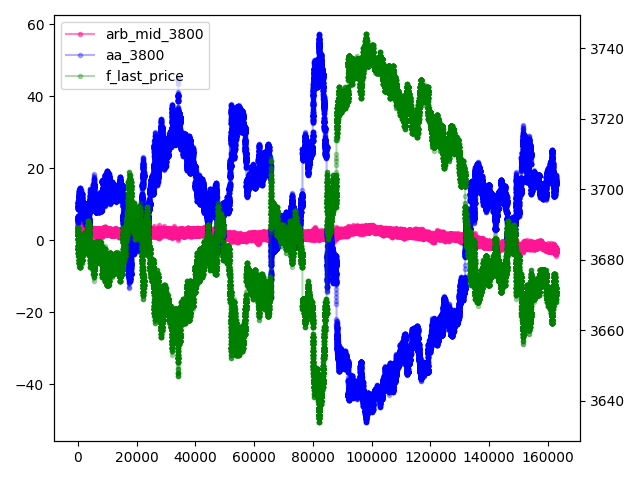

In [75]:
plt.close()

_price = 3800

fig, ax1 = plt.subplots()
ax1.plot(xx['arb_mid_%s' % _price].values[-_start:], marker='.', label='arb_mid_%s' % _price, color='deeppink', alpha=.5)
ax1.plot(xx['aa_%s' % _price].values[-_start:], marker='.', label='aa_%s' % _price, color='b', alpha=.3)

ax2 = ax1.twinx()
# ax2.plot(xx['aa_%s' % _price].values[-_start:], marker='.', label='aa_%s' % _price, color='b', alpha=.3)
ax2.plot(xx['f_last_price'].values[-_start:], marker='.', label='f_last_price', color='g', alpha=.3)

lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc=0)


fig.tight_layout()
plt.show()

In [4]:
ddd = pd.read_hdf('D:/rb2410 x.h5')

In [ ]:
ddd.head()

In [88]:
ddd[['arb_3900', 'negative_3900', 'positive_3900',
       'rb2410_buy_3900', 'rb2410_sell_3900', 'arb_3750', 'negative_3750',
       'positive_3750', 'rb2410_buy_3750', 'rb2410_sell_3750']]

,arb_3900,negative_3900,positive_3900,rb2410_buy_3900,rb2410_sell_3900,arb_3750,negative_3750,positive_3750,rb2410_buy_3750,rb2410_sell_3750
2024-05-16 14:26:02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-05-16 14:26:00,NaN,NaN,NaN,NaN,NaN,1.00,1.50,2.00,3.00,-2.00
2024-05-16 14:25:59,-5.50,2.50,8.00,2.50,-1.50,1.00,1.50,2.00,3.00,-2.00
2024-05-16 14:26:03,-4.50,2.50,8.00,3.50,-2.50,2.00,2.00,2.00,4.00,-3.00
2024-05-16 14:26:04,-4.50,2.50,8.00,3.50,-2.50,2.00,2.00,1.50,3.50,-2.50
...,...,...,...,...,...,...,...,...,...,...
2024-05-16 14:59:57,1.50,3.50,4.00,5.50,-4.50,2.00,2.50,2.00,4.00,-3.00
2024-05-16 14:59:58,1.50,3.50,4.00,5.50,-4.50,2.00,2.50,2.00,4.00,-3.00
2024-05-16 14:59:59,0.50,4.00,5.00,5.50,-3.50,2.00,2.50,2.00,4.00,-3.00
2024-05-16 15:00:00,1.50,4.00,4.00,5.50,-4.50,2.00,2.50,2.00,4.00,-3.00


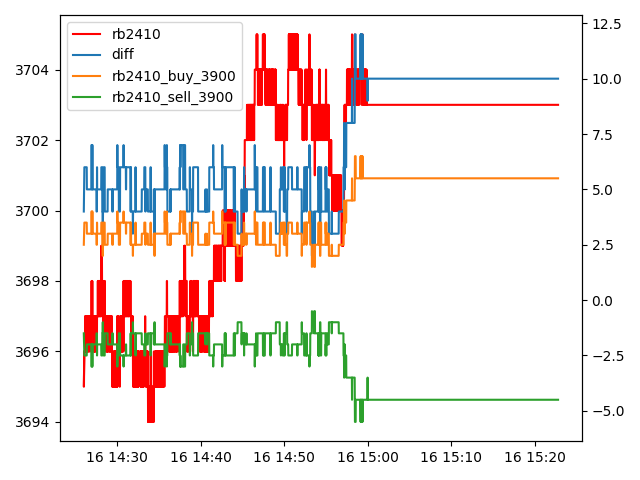

In [101]:
plt.close()

fig, ax1 = plt.subplots()
ax1.plot(ddd['rb2410'], label='rb2410', color='r')

ax2 = ax1.twinx()
ax2.plot(ddd['rb2410_buy_3900'] - ddd['rb2410_sell_3900'], label='diff')
ax2.plot(ddd['rb2410_buy_3900'], label='rb2410_buy_3900')
ax2.plot(ddd['rb2410_sell_3900'], label='rb2410_sell_3900')

lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc=0)

fig.tight_layout()
plt.show()

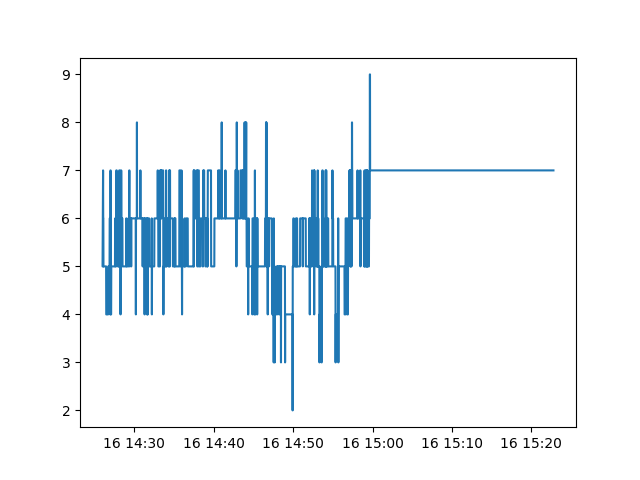

In [93]:
plt.close()
plt.plot(ddd['rb2410_buy_3750'] - ddd['rb2410_sell_3750'])
plt.show()

In [6]:
from sqlalchemy import create_engine

In [11]:
engine = create_engine('sqlite://', echo=False)

In [13]:
ddd.to_sql(name='rb2410', con=engine, if_exists='replace')

2042

In [82]:
pd.set_option('display.float_format', '{:.2f}'.format)

In [83]:
df.iloc[8000:]

,f_last_price,f_sell_price,f_buy_price,c_last_price_rb2410C3350,c_sell_price_rb2410C3350,c_buy_price_rb2410C3350,c_last_price_rb2410C3400,c_sell_price_rb2410C3400,c_buy_price_rb2410C3400,c_last_price_rb2410C3450,...,negative_price_3950,positive_price_3950,arb_4000,spread_4000,spread_c_4000,spread_p_4000,negative_4000,positive_4000,negative_price_4000,positive_price_4000
datetime,,,,,,,,,,,,,,,,,,,,,
2024-04-26 13:45:20,3676.00,3676.00,3677.00,362.50,357.50,359.50,321.00,316.50,319.00,268.50,...,5901.80,-9050.60,-6.50,4.50,0.50,3.00,-2.50,-2.00,6047.40,-9477.60
2024-04-26 13:45:21,3676.00,3676.00,3677.00,362.50,357.50,359.50,321.00,316.50,319.00,268.50,...,5901.80,-9050.60,-6.50,4.50,0.50,3.00,-2.50,-2.00,6047.40,-9477.60
2024-04-26 13:45:22,3676.00,3676.00,3677.00,362.50,357.50,359.50,321.00,316.50,319.00,268.50,...,5901.80,-9050.60,-6.50,4.50,0.50,3.00,-2.50,-2.00,6047.40,-9477.60
2024-04-26 13:45:23,3677.00,3677.00,3678.00,362.50,357.50,359.50,321.00,316.50,319.00,268.50,...,5903.40,-9051.40,-5.50,4.50,0.50,3.00,-1.50,-3.00,6049.00,-9479.20
2024-04-26 13:45:24,3677.00,3677.00,3678.00,362.50,357.50,360.00,321.00,316.50,320.00,268.50,...,5901.80,-9051.40,-5.50,5.00,0.50,3.50,-2.50,-2.50,6047.40,-9474.20
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-05-15 22:56:55,3621.00,3619.00,3620.00,310.00,299.50,302.50,262.00,261.50,264.00,227.50,...,6037.40,-9346.60,0.50,6.50,1.00,4.50,-7.50,1.00,6165.40,-9796.20
2024-05-15 22:56:56,3620.00,3619.00,3620.00,310.00,299.00,301.50,262.00,261.00,264.00,227.50,...,6037.40,-9356.60,-0.50,8.50,1.00,6.50,-7.50,-1.00,6165.40,-9816.20
2024-05-15 22:56:57,3619.00,3619.00,3620.00,310.00,298.50,301.50,262.00,261.00,264.00,227.50,...,6037.40,-9356.60,-1.50,8.50,1.00,6.50,-7.50,-1.00,6165.40,-9816.20


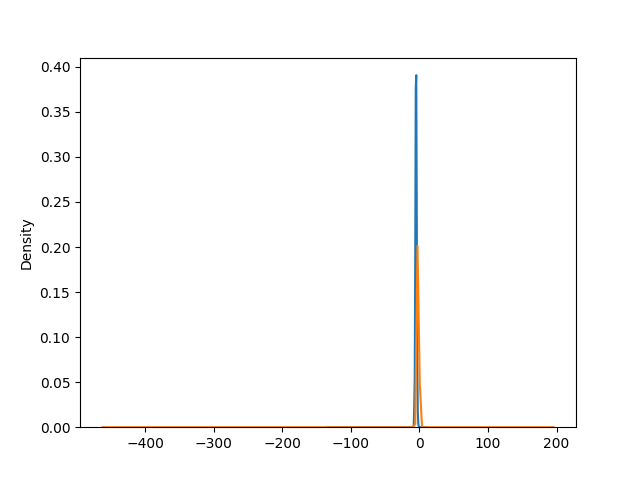

In [30]:
plt.close()
# for _price in prices[11:12]:
_price = 6100 # 3900
_start = 20000

fig, ax1 = plt.subplots()

sn.kdeplot(df['negative_%s' % _price].values[-_start:], ax=ax1)
sn.kdeplot(df['positive_%s' % _price].values[-_start:], ax=ax1)

plt.show()

### 盒式套利

In [119]:
df_box = fdf # .merge(cdf, how='left', left_index=True, right_index=True)

for c_symbol in c_symbols:
    df_box = df_box.merge(cdfs[c_symbol], how='left', left_index=True, right_index=True)

for p_symbol in p_symbols:
    df_box = df_box.merge(pdfs[p_symbol], how='left', left_index=True, right_index=True)

In [120]:
df_box['min'] = df_box.index.hour * 60 + df_box.index.minute

In [121]:
_dfs_box = []
for s, e in min_range:
    _dfs_box.append(df[(df['min'] > s) & (df['min'] < e)])

In [122]:
df_box = pd.concat(_dfs_box, axis=0).sort_index()

In [123]:
df_box = df_box.ffill()

In [124]:
# 盒式套利
for price1 in prices:
    for price2 in prices:
        if price1 < price2:
            price_diff = price2 - price1

            _d = pd.concat(
                [
                    df_box['c_buy_price_%sC%s' % (f_symbol, price1)] - df_box['p_sell_price_%sP%s' % (f_symbol, price1)] - df_box['c_sell_price_%sC%s' % (f_symbol, price2)] + df_box['p_buy_price_%sP%s' % (f_symbol, price2)] - price_diff,
                    df_box['c_buy_price_%sC%s' % (f_symbol, price2)] - df_box['p_sell_price_%sP%s' % (f_symbol, price2)] - df_box['c_sell_price_%sC%s' % (f_symbol, price1)] + df_box['p_buy_price_%sP%s' % (f_symbol, price1)] + price_diff,

                    (((df_box['c_buy_price_%sC%s' % (f_symbol, price1)] + df_box['c_sell_price_%sC%s' % (f_symbol, price1)])) / 2 -
                    ((df_box['p_buy_price_%sP%s' % (f_symbol, price1)] + df_box['p_sell_price_%sP%s' % (f_symbol, price1)])) / 2) -
                    
                    (((df_box['c_buy_price_%sC%s' % (f_symbol, price2)] + df_box['c_sell_price_%sC%s' % (f_symbol, price2)])) / 2 -
                    ((df_box['p_buy_price_%sP%s' % (f_symbol, price2)] + df_box['p_sell_price_%sP%s' % (f_symbol, price2)])) / 2) - price_diff
                ],
                axis=1, 
                keys=['negative_box_%s_%s' % (price1, price2), 'positive_box_%s_%s' % (price1, price2), 'box_%s_%s' % (price1, price2)]
            )
            
            
            
            df_box = pd.concat([df_box, _d], axis=1)
            

In [125]:
# df_box = df_box[(df_box > -1000000) & (df_box < 1000000)]

In [126]:
df_box.head()

,f_last_price,f_sell_price,f_buy_price,c_last_price_rb2410C3650,c_sell_price_rb2410C3650,c_buy_price_rb2410C3650,c_last_price_rb2410C3700,c_sell_price_rb2410C3700,c_buy_price_rb2410C3700,c_last_price_rb2410C3750,...,box_3650_3800,negative_box_3700_3750,positive_box_3700_3750,box_3700_3750,negative_box_3700_3800,positive_box_3700_3800,box_3700_3800,negative_box_3750_3800,positive_box_3750_3800,box_3750_3800
datetime,,,,,,,,,,,,,,,,,,,,,
2024-03-04 09:04:00,3746.00,3746.00,3747.00,224.00,201.00,238.50,196.00,172.00,211.50,161.00,...,-3.50,74.00,70.50,1.75,72.00,71.00,0.50,74.00,76.50,-1.25
2024-03-04 09:04:01,3746.00,3746.00,3747.00,224.00,201.00,238.50,196.00,172.00,211.50,161.00,...,-3.50,74.00,70.50,1.75,72.00,71.00,0.50,74.00,76.50,-1.25
2024-03-04 09:04:02,3746.00,3746.00,3747.00,224.00,201.00,238.50,196.00,172.00,211.50,161.00,...,-3.50,74.00,70.50,1.75,72.00,71.00,0.50,74.00,76.50,-1.25
2024-03-04 09:04:03,3746.00,3746.00,3747.00,224.00,201.00,238.50,196.00,172.00,211.50,161.00,...,-3.50,74.00,70.50,1.75,72.00,71.00,0.50,74.00,76.50,-1.25
2024-03-04 09:04:04,3746.00,3746.00,3747.00,224.00,201.00,238.50,196.00,172.00,211.50,161.00,...,-3.50,74.00,70.50,1.75,72.00,71.00,0.50,74.00,76.50,-1.25


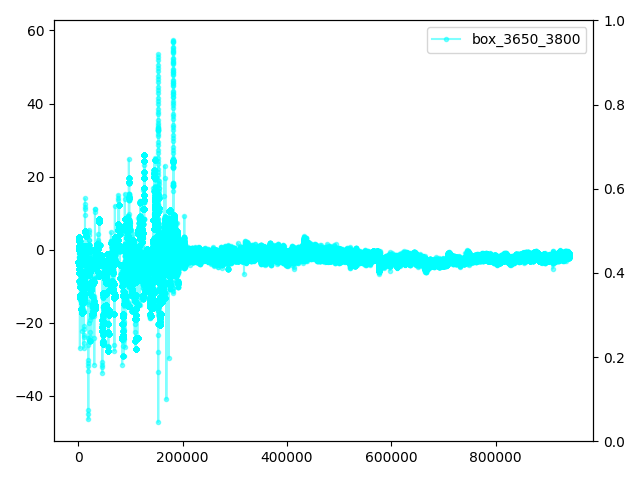

In [131]:
plt.close()
# for _price in prices[11:12]:
_price1 = 3650 # 3900 6100
_price2 = 3800
_start = 2000000

fig, ax1 = plt.subplots()
# ax1.plot(df['arb_%s' % _price].values[-_start:], label='arb_%s' % _price, color='g')
# ax1.plot(df_box['negative_box_%s_%s' % (_price1, _price2)].values[-_start:], label='negative_box_%s_%s' % (_price1, _price2), color='y')
# ax1.plot(df_box['positive_box_%s_%s' % (_price1, _price2)].values[-_start:], label='positive_box_%s_%s' % (_price1, _price2), color='b')
ax1.plot(df_box['box_%s_%s' % (_price1, _price2)].values[-_start:], marker='.', label='box_%s_%s' % (_price1, _price2), color='aqua', alpha=.5)

ax2 = ax1.twinx()
# ax2.plot(df_box['spread_c_%s' % _price].values[-_start:], label='spread_c_%s' % _price, color='r')
# ax2.plot(df_box['f_last_price'].values[-_start:], label='f_last_price', color='r')

lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc=0)


fig.tight_layout()
plt.show()

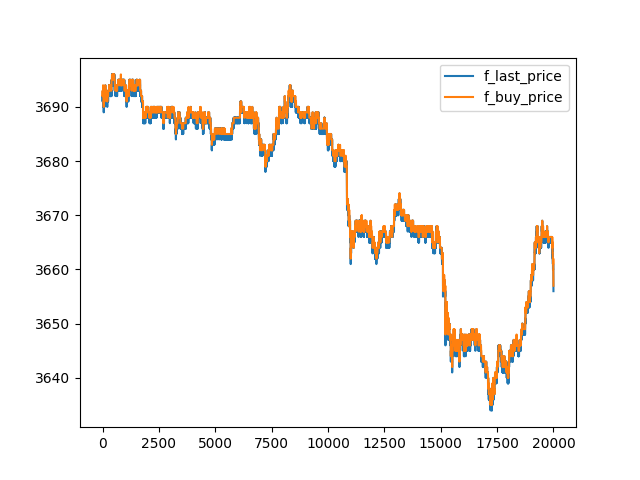

In [56]:
plt.close()

_start = 20000
plt.plot(df['f_last_price'].values[-_start:], label='f_last_price')
plt.plot(df['f_buy_price'].values[-_start:], label='f_buy_price')
# plt.plot(df['f_sell_price'].values[-_start:], label='f_sell_price')


plt.legend()
plt.show()

In [47]:
df.columns

Index(['f_last_price', 'f_sell_price', 'f_buy_price',
       'c_last_price_rb2410C3250', 'c_sell_price_rb2410C3250',
       'c_buy_price_rb2410C3250', 'c_last_price_rb2410C3300',
       'c_sell_price_rb2410C3300', 'c_buy_price_rb2410C3300',
       'c_last_price_rb2410C3350',
       ...
       'negative_box_4150_4250', 'positive_box_4150_4250',
       'negative_box_4150_4300', 'positive_box_4150_4300',
       'negative_box_4200_4250', 'positive_box_4200_4250',
       'negative_box_4200_4300', 'positive_box_4200_4300',
       'negative_box_4250_4300', 'positive_box_4250_4300'],
      dtype='object', length=707)

In [40]:
# _df[150:200]

In [63]:
plt.close()

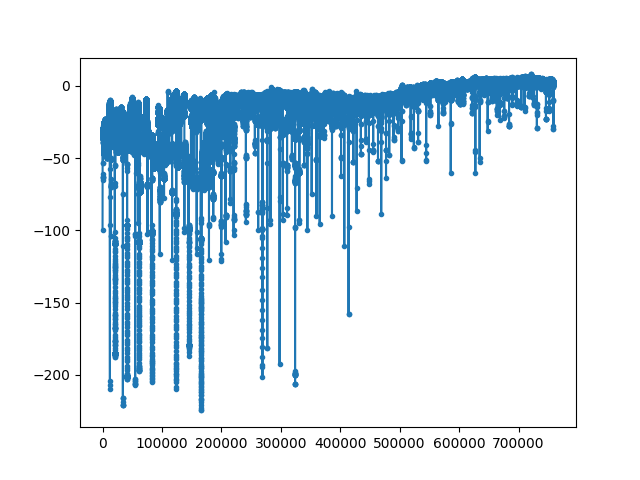

In [64]:
plt.plot(df.negative.values, marker='.')

In [46]:
plt.close()

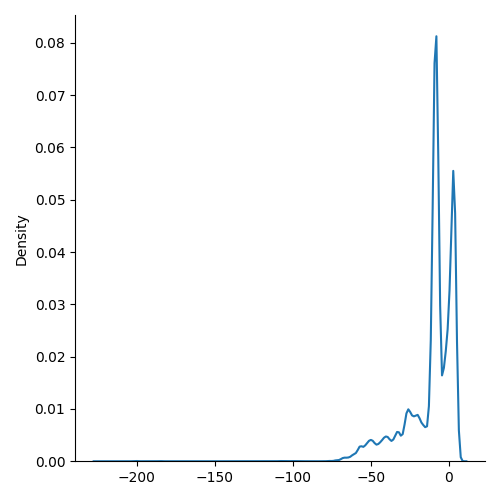

In [47]:
sn.displot(df.negative.values, kind='kde')

In [71]:
plt.close()

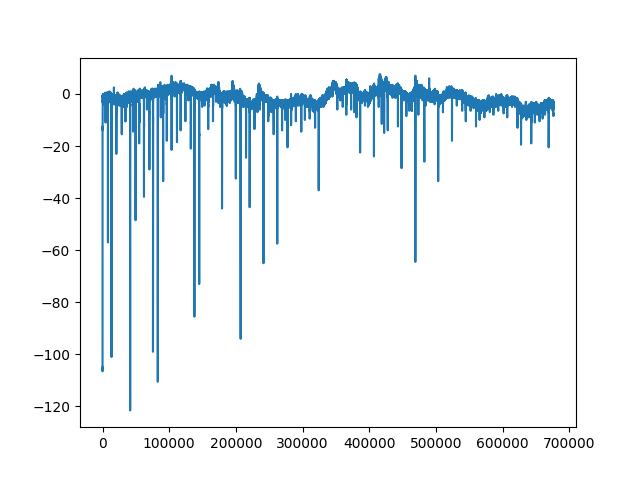

In [72]:
plt.plot(df.positive.values)

In [73]:
plt.close()

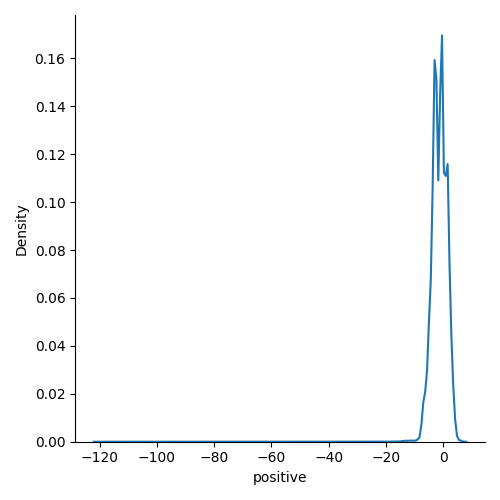

In [74]:
sn.displot(df.positive, kind='kde')

In [7]:
ddd = load('SHFE', 'rb2410P3900', '2024-05-01', resample='1s')

load Y:/ctp_data\2024-05-06\SHFE.rb2410P3900.h5
load Y:/ctp_data\2024-05-07\SHFE.rb2410P3900.h5
load Y:/ctp_data\2024-05-08\SHFE.rb2410P3900.h5
load Y:/ctp_data\2024-05-09\SHFE.rb2410P3900.h5
load Y:/ctp_data\2024-05-10\SHFE.rb2410P3900.h5
load Y:/ctp_data\2024-05-13\SHFE.rb2410P3900.h5


In [8]:
ddd['ask_price1']

,datetime,last_price,volume,amount,open_interest,bid_price1,bid_volume1,ask_price1,ask_volume1
datetime,,,,,,,,,
2024-05-06 09:00:00,2024-05-06 09:00:00.500,294.0,0.0,0.0,285.0,275.0,2.0,3.310000e+02,2.0
2024-05-06 09:00:01,2024-05-06 09:00:00.500,294.0,0.0,0.0,285.0,275.0,2.0,3.310000e+02,2.0
2024-05-06 09:00:02,2024-05-06 09:00:00.500,294.0,0.0,0.0,285.0,275.0,2.0,3.310000e+02,2.0
2024-05-06 09:00:03,2024-05-06 09:00:03.500,294.0,0.0,0.0,285.0,275.0,2.0,3.085000e+02,1.0
2024-05-06 09:00:04,2024-05-06 09:00:04.000,294.0,0.0,0.0,285.0,275.0,2.0,3.085000e+02,1.0
...,...,...,...,...,...,...,...,...,...
2024-05-13 22:59:55,2024-05-13 22:59:33.500,280.5,0.0,51515.0,305.0,276.5,20.0,2.960000e+02,20.0
2024-05-13 22:59:56,2024-05-13 22:59:33.500,280.5,0.0,51515.0,305.0,276.5,20.0,2.960000e+02,20.0
2024-05-13 22:59:57,2024-05-13 22:59:57.500,280.5,0.0,51515.0,305.0,276.5,20.0,2.960000e+02,20.0


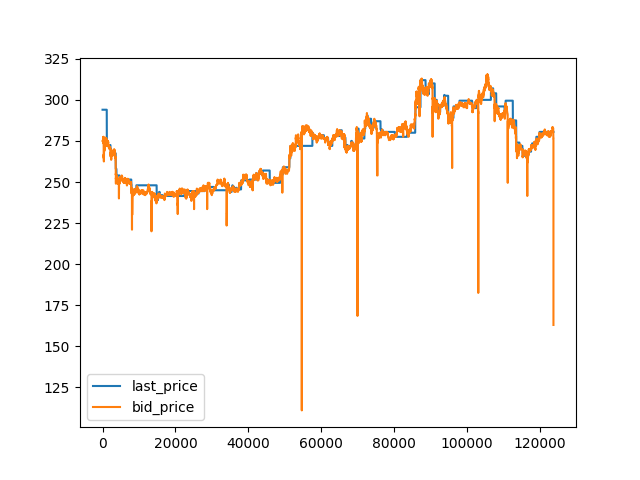

In [11]:
plt.close()

plt.plot(ddd.last_price.values, label='last_price')
plt.plot(ddd.bid_price1.values, label='bid_price')
# plt.plot(ddd.ask_price1.values, label='ask_price')

plt.legend()
plt.show()